# 1. Exploration et prétraitement des traces réelles TON_IoT

**Objectif.** Comprendre les données que nous avons vraiment, puis les préparer pour la suite :
fusionner les trois capteurs sur une grille de temps commune et calculer les features.

Trois traces normales (dossier `notebook/Raw/Normal`) : la **météo** (extérieur), le
**thermostat** (la salle) et le **frigo** (le produit, à garder entre 2 et 8 °C).
Elles couvrent du 31 mars au 4 avril 2019.

In [1]:
%%capture
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").is_dir())
sys.path[:0] = [str(ROOT / "backend"), str(ROOT / "backend" / "scripts")]
import build_dataset as bd
import transmission_real as tr
import transmission_models as tm
import transmission_study as ts
from app.api.v1 import phase2
from app.core import paths

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (11, 3.5)
SEED = tr.SEED
COLS = {"weather": "temperature", "fridge": "fridge_temperature", "thermostat": "current_temperature"}
EPISODES_PATH = paths.PROCESSED_DIR / "episodes_transmission_reel.json"
MODEL_DIR = paths.MODELS_DIR / "transmission_reel"

In [2]:
real = bd.load_normal_traces()

  weather      72,245 lignes  2019-03-31 12:36:52 -> 2019-04-04 07:50:01  temperature [20.5 ; 49.5]


  fridge       57,334 lignes  2019-03-31 12:36:52 -> 2019-04-04 07:50:01  fridge_temperature [1.0 ; 14.0]


  thermostat  104,410 lignes  2019-03-31 12:36:52 -> 2019-04-04 07:49:59  current_temperature [25.0 ; 35.0]


## 1.1 Aperçu des fichiers bruts

In [3]:
for s, c in COLS.items():
    print(f"── {s} ({len(real[s]):,} lignes)")
    display(real[s].head(3))

── weather (72,245 lignes)


,temperature,pressure,humidity,datetime,label
0,31.788508,1.035,32.036579,2019-03-31 12:36:52,0
1,41.630997,1.035,30.886165,2019-03-31 12:36:53,0
2,42.256959,1.035,19.755908,2019-03-31 12:36:54,0


── fridge (57,334 lignes)


,fridge_temperature,temp_condition,datetime,label
0,13.10,high,2019-03-31 12:36:52,0
1,8.65,high,2019-03-31 12:36:53,0
2,2.00,low,2019-03-31 12:36:54,0


── thermostat (104,410 lignes)


,current_temperature,datetime,_status,thermostat_status,label
0,25.0,2019-03-31 12:36:52,NaN,0,0
1,25.0,2019-03-31 12:36:53,NaN,0,0
2,25.0,2019-03-31 12:36:54,NaN,0,0


In [4]:
rows = []
for s, c in COLS.items():
    d = real[s]["datetime"]
    dt = d.diff().dt.total_seconds().dropna()
    rows.append({"capteur": s, "lignes": len(d), "début": d.min(), "fin": d.max(),
                 "pas médian (s)": dt.median(), "trous > 10 min": int((dt > 600).sum()),
                 "plus grand trou (h)": round(dt.max() / 3600, 1)})
pd.DataFrame(rows)

,capteur,lignes,début,fin,pas médian (s),trous > 10 min,plus grand trou (h)
0,weather,72245,2019-03-31 12:36:52,2019-04-04 07:50:01,4.0,4,26.2
1,fridge,57334,2019-03-31 12:36:52,2019-04-04 07:50:01,5.0,4,26.2
2,thermostat,104410,2019-03-31 12:36:52,2019-04-04 07:49:59,2.0,4,26.2


Les trois traces durent **3 jours et 19 heures**, avec un **trou de 26 heures** au milieu.
Chaque capteur envoie une mesure toutes les 2 à 5 secondes.

## 1.2 À quoi ressemblent les mesures ?

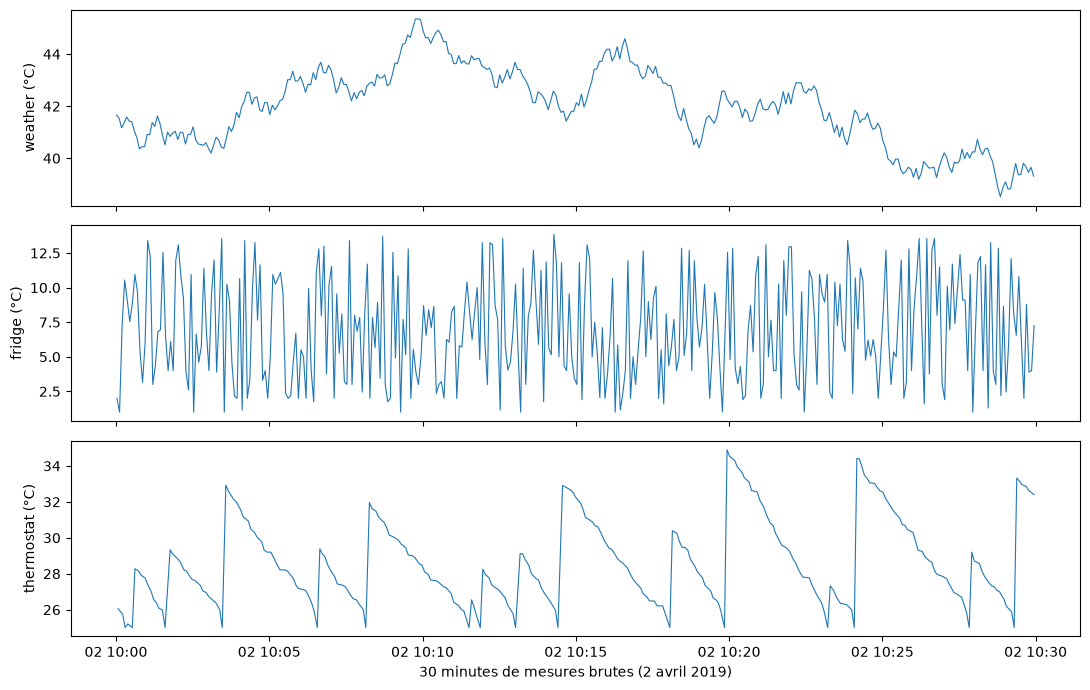

In [5]:
t0 = pd.Timestamp("2019-04-02 10:00"); t1 = t0 + pd.Timedelta(minutes=30)
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, (s, c) in zip(axes, COLS.items()):
    d = real[s].set_index("datetime")[c][t0:t1]
    ax.plot(d.index, d.values, lw=0.8)
    ax.set_ylabel(f"{s} (°C)")
axes[-1].set_xlabel("30 minutes de mesures brutes (2 avril 2019)")
plt.tight_layout()

3 histogrammes → la distribution des valeurs (quelles valeurs reviennent le plus)

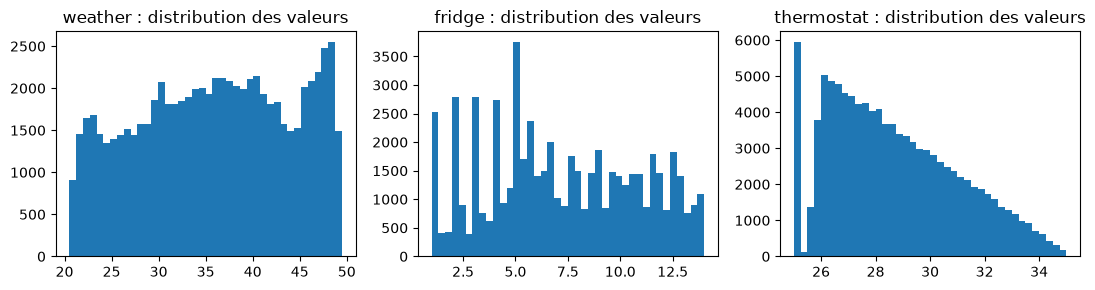

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, (s, c) in zip(axes, COLS.items()):
    ax.hist(real[s][c], bins=40)
    ax.set_title(f"{s} : distribution des valeurs")
plt.tight_layout()

**Observation.** Le frigo saute d'une valeur à l'autre entre 1 et 14 °C à chaque mesure, sans
mémoire : chaque mesure est indépendante de la précédente. Le thermostat reste à 25 °C avec des
sauts aléatoires jusqu'à 35 °C. La météo suit un cycle régulier de 5 valeurs.

Ce ne sont donc pas des courbes de température « physiques » : il n'y a ni journée, ni saison,
ni lien entre la salle et le frigo. Cela compte pour la suite : une attaque ne sera visible que si
elle change le **niveau moyen**, la **dispersion**, ou **répète des valeurs exactes**.

## 1.3 Fusion sur une grille de 5 secondes

Les trois capteurs n'envoient pas leurs mesures aux mêmes instants. On les ramène sur une grille
commune de 5 s (moyenne des mesures du pas). Les trous de moins d'une minute sont comblés par la
dernière valeur ; le reste (le trou de 26 h) est supprimé.

pas_grille:Nombre de cases de 5 s si la période était continue (trou de 26 h compris).


pas_conserves: Nombre de lignes réellement conservées après suppression des grands trous

In [7]:
base, info = tr.fuse_real(real)
print(info)
base.head()

{'pas': '5s', 'pas_grille': 65679, 'pas_conserves': 44443, 'debut': '2019-03-31 12:36:50', 'fin': '2019-04-04 07:50:00'}


,datetime,weather_temp,fridge_temp,thermostat_temp,fridge_cond,thermo_status
0,2019-03-31 12:36:50,38.56,7.92,25.00,low,0
1,2019-03-31 12:36:55,37.79,6.09,25.49,high,0
2,2019-03-31 12:37:00,37.97,5.64,25.14,low,0
3,2019-03-31 12:37:05,37.85,5.31,26.33,high,0
4,2019-03-31 12:37:10,37.73,9.10,31.53,low,1


In [8]:
prof = tr.profile(base)
tableau = pd.DataFrame({s: prof[s] for s in COLS}).T
tableau.columns = ["moyenne (°C)", "écart-type (°C)", "autocorrélation à 5 s", "autocorrélation à 1 min"]
print(f"corrélation frigo ↔ salle (effet météo retiré) : {prof['correlation_frigo_salle_meteo_fixee']:.2f}")
tableau

corrélation frigo ↔ salle (effet météo retiré) : 0.00


,moyenne (°C),écart-type (°C),autocorrélation à 5 s,autocorrélation à 1 min
weather,34.79,7.14,0.997,0.978
fridge,7.18,3.40,0.005,0.008
thermostat,28.67,1.68,0.438,-0.007


Deux chiffres à retenir :

- **autocorrélation du frigo ≈ 0** : une mesure ne dit rien sur la suivante ;
- **corrélation frigo ↔ salle = 0** : les deux capteurs ne se suivent pas. On ne peut donc pas
  utiliser la salle comme témoin du frigo ; chaque capteur doit être surveillé pour lui-même.

## 1.4 Features (prétraitement)

Pour chaque capteur et chaque ligne, on calcule des indicateurs qui **ne regardent que le passé**, sur des
fenêtres d'**au plus 15 minutes** (la zone de garde du découpage, 20 min, couvre cette fenêtre plus la règle de
persistance des alertes) :

| Groupe | Features | Ce qu'elles captent |
| --- | --- | --- |
| Valeur et variation | `*_temp`, `*_diff_1` | la mesure, et son saut depuis la mesure précédente |
| Moyennes glissantes | `*_mean_1min`, `_5min`, `_15min` | le niveau moyen à trois échelles |
| Écarts-types glissants | `*_std_1min`, `_5min`, `_15min` | la dispersion ; un capteur figé donne 0 |
| Variation absolue moyenne | `*_absdiff_5min` | un capteur figé ou des valeurs forgées varient peu d'une mesure à l'autre |
| Forme de la distribution (frigo, thermostat) | `*_min_*`, `*_max_*`, `*_q10_*`, `*_q90_*` sur 5 et 15 min | un décalage de −0,5 °C déplace le haut et le bas de la distribution glissante (les traces sont bornées : frigo entre 1 et 14 °C) bien avant que la moyenne ne bouge |
| Séquence déjà vue | `*_repeat_2min` | 1 si les 2 dernières minutes ont déjà été transmises telles quelles (rejeu exact) |
| Entre capteurs (résidus) | `fridge_thermostat_diff`, `weather_*_diff`, leur moyenne sur 15 min | les écarts entre capteurs |
| États | `fridge_cond_enc`, `thermo_status` | les indicateurs fournis par les capteurs |

La moyenne lissée exponentielle (EWMA) de la version précédente est **retirée** : sa mémoire n'est pas bornée,
elle aurait traversé la zone de garde. Pas d'heure ni de saison : avec 62 heures de données, elles ne serviraient
qu'à mémoriser.

In [9]:
df_feat, feats = tm.engineer(base)
print(len(feats), "features")
feats

53 features


['weather_temp',
 'weather_diff_1',
 'weather_mean_1min',
 'weather_std_1min',
 'weather_mean_5min',
 'weather_std_5min',
 'weather_mean_15min',
 'weather_std_15min',
 'weather_absdiff_5min',
 'weather_repeat_2min',
 'fridge_temp',
 'fridge_diff_1',
 'fridge_mean_1min',
 'fridge_std_1min',
 'fridge_mean_5min',
 'fridge_std_5min',
 'fridge_mean_15min',
 'fridge_std_15min',
 'fridge_min_5min',
 'fridge_max_5min',
 'fridge_q10_5min',
 'fridge_q90_5min',
 'fridge_min_15min',
 'fridge_max_15min',
 'fridge_q10_15min',
 'fridge_q90_15min',
 'fridge_absdiff_5min',
 'fridge_repeat_2min',
 'thermostat_temp',
 'thermostat_diff_1',
 'thermostat_mean_1min',
 'thermostat_std_1min',
 'thermostat_mean_5min',
 'thermostat_std_5min',
 'thermostat_mean_15min',
 'thermostat_std_15min',
 'thermostat_min_5min',
 'thermostat_max_5min',
 'thermostat_q10_5min',
 'thermostat_q90_5min',
 'thermostat_min_15min',
 'thermostat_max_15min',
 'thermostat_q10_15min',
 'thermostat_q90_15min',
 'thermostat_absdiff_5min',

In [10]:
df_feat[["datetime"] + feats[:10]].iloc[2000:2005].round(3)

,datetime,weather_temp,weather_diff_1,weather_mean_1min,weather_std_1min,weather_mean_5min,weather_std_5min,weather_mean_15min,weather_std_15min,weather_absdiff_5min,weather_repeat_2min
2000,2019-04-01 17:34:00,41.65,0.06,42.234,0.519,42.031,0.545,41.655,0.640,0.120,0.0
2001,2019-04-01 17:34:05,41.62,-0.03,42.113,0.477,42.035,0.541,41.662,0.631,0.120,0.0
2002,2019-04-01 17:34:10,41.39,-0.23,41.983,0.443,42.033,0.543,41.668,0.623,0.121,0.0
2003,2019-04-01 17:34:15,41.33,-0.06,41.847,0.363,42.034,0.541,41.674,0.615,0.118,0.0
2004,2019-04-01 17:34:20,41.20,-0.13,41.732,0.332,42.028,0.549,41.680,0.605,0.116,0.0


In [11]:
out = paths.PROCESSED_DIR / "traces_reelles_5s.csv"
base.to_csv(out, index=False)
print("Traces fusionnées enregistrées :", out, f"({len(base):,} lignes)")

Traces fusionnées enregistrées : /srv/vigilochain/app/data/processed/traces_reelles_5s.csv (44,443 lignes)
